# Structural Steel MFA 1931-2100

## Imports

In [18]:
import pandas as pd
import numpy as np
from odym import dynamic_stock_model as dsm
import weibull
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm
from scipy.stats import qmc
from scipy.stats import weibull_min
import itertools
from pathlib import Path


## Read in Data

In [2]:
BASE_DIR = Path.cwd().parent
fig_dir = BASE_DIR / 'figures'

df_steel_forecast = pd.read_csv(BASE_DIR / 'output_data/steel_forecast.csv', index_col=0)

## Perform MFA

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Define survival function
# ─────────────────────────────────────────────────────────────────────────────
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull': 
        lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

Text(0.5, 0, 'Age to Failuire')

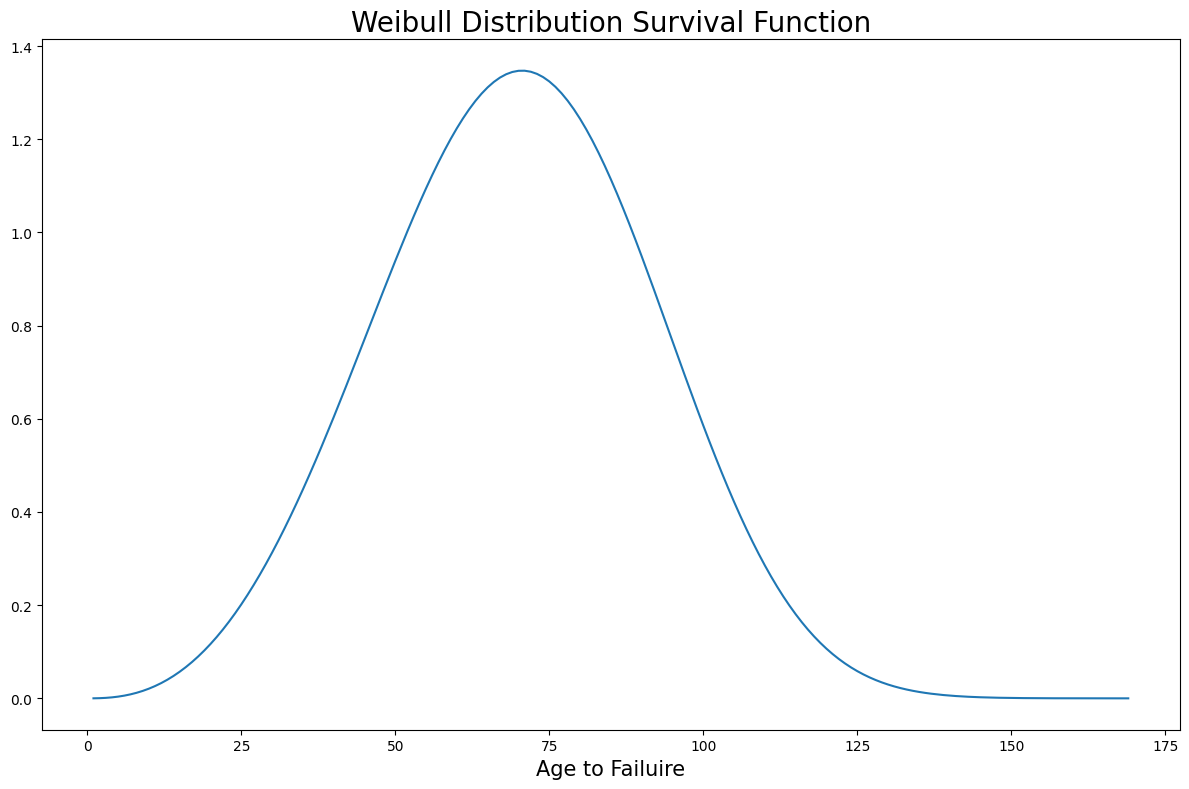

In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# See weibull shape
# ─────────────────────────────────────────────────────────────────────────────
lt_buildings = generate_lt('Weibull',par1=3.5,par2=77.7)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [21]:
## Get params
years = df_steel_forecast.index

years = np.array(years)
n_years = len(years)


In [22]:
def median_to_scale(median, shape):
    return median / np.log(2) ** (1 / shape)


def build_lifetime_scenarios(inflow_series, years, base_shape=3.5, base_median=70,
                                change_year=2024, medians=range(70, 111)):
    """
    Stock-driven lifetime scenarios (new cohorts only).
    1. Baseline: inflow-driven with the base lifetime -> stock = service level.
    2. Each scenario: stock-driven with that same stock and a longer lifetime
       for cohorts entering after change_year -> required inflow.
    Returns a dict of DSM results keyed 'median_70', 'median_71', ...
    """
    results = {}
    n_years = len(years)
    shape_array = np.full(n_years, base_shape)
    base_scale = median_to_scale(base_median, base_shape)
    I_base = np.array(inflow_series, dtype=float)

    # 1. Baseline stock (service level implied by the regression inflow)
    base_DSM = dsm.DynamicStockModel(
        t=years, i=I_base,
        lt={'Type': 'Weibull', 'Shape': shape_array,
            'Scale': np.full(n_years, base_scale)})
    base_DSM.compute_s_c_inflow_driven()
    S_base = base_DSM.compute_stock_total()

    # 2. Lifetime scenarios
    for med in medians:
        new_scale = median_to_scale(med, base_shape)
        scale_array = np.where(years <= change_year, base_scale, new_scale)

        steel_DSM = dsm.DynamicStockModel(
            t=years, s=S_base,
            lt={'Type': 'Weibull', 'Shape': shape_array, 'Scale': scale_array})

        stock_by_cohort, O_C, I_steel = steel_DSM.compute_stock_driven_model(
            NegativeInflowCorrect=True)
        CheckStr = steel_DSM.dimension_check()
        S_steel = steel_DSM.compute_stock_total()
        DS_steel = steel_DSM.compute_stock_change()
        O_steel = steel_DSM.compute_outflow_total()

        results[f'lifetime_{med}'] = {
            'dsm': steel_DSM,
            'stock_by_cohort': stock_by_cohort,
            'check': CheckStr,
            'S_steel': S_steel,
            'O_C': O_C,
            'DS_steel': DS_steel,
            'O_steel': O_steel,
            'I_steel': I_steel,
            'I_reduction': I_base - I_steel,
            'lifetime_median': med,
            'lifetime_scale': new_scale,
        }

    return results

In [23]:
scenario_results_low  = build_lifetime_scenarios(df_steel_forecast['ssp3'], years)
scenario_results_mid  = build_lifetime_scenarios(df_steel_forecast['ssp2'], years)
scenario_results_high = build_lifetime_scenarios(df_steel_forecast['ssp4'], years)

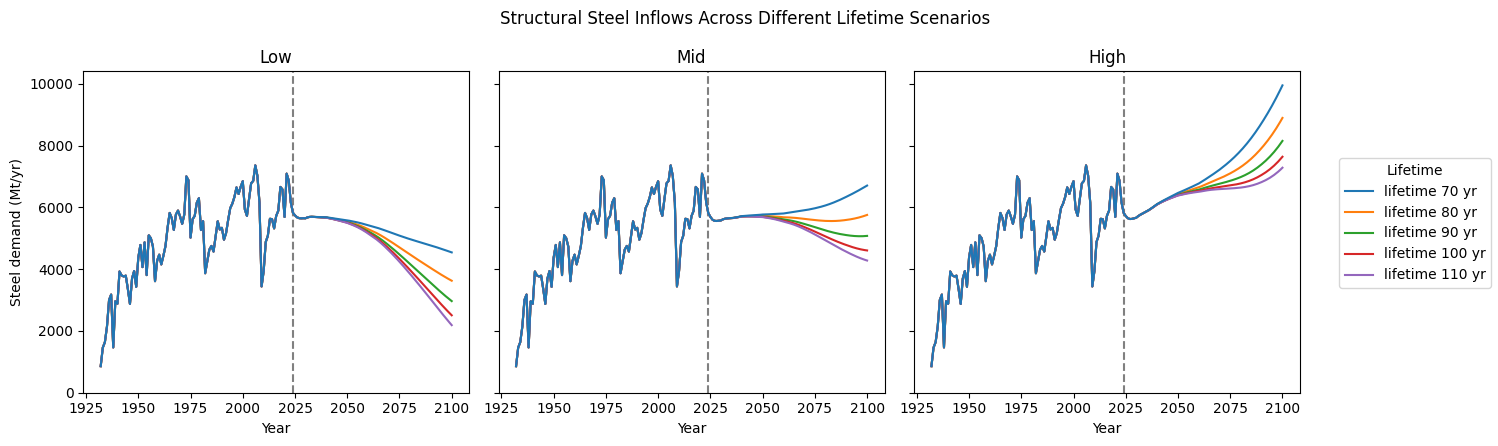

In [24]:
# ─────────────────────────────────────────────────────────────────────────────
# Plot inflows given different lifetime scenarios
# ─────────────────────────────────────────────────────────────────────────────
scenarios = {
    'Low':  scenario_results_low,    # ssp3
    'Mid':  scenario_results_mid,    # ssp2
    'High': scenario_results_high,   # ssp4
}
lifetimes = [70, 80, 90, 100, 110]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

for ax, (label, res) in zip(axes, scenarios.items()):
    for lt in lifetimes:
        ax.plot(years, res[f'lifetime_{lt}']['I_steel'], label=f'lifetime {lt} yr',
                zorder=5 if lt == 70 else 2)   # 70-yr line drawn on top
    ax.axvline(2024, ls='--', c='grey', zorder=1)
    ax.set_title(label)
    ax.set_xlabel('Year')

axes[0].set_ylabel('Steel demand (Mt/yr)')
axes[0].set_ylim(bottom=0)
fig.suptitle('Structural Steel Inflows Across Different Lifetime Scenarios')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center right', frameon=True, title='Lifetime')

fig.savefig(fig_dir / 'inflows_per_lt')
plt.tight_layout(rect=[0, 0, 0.88, 1]) 

In [25]:
# ─────────────────────────────────────────────────────────────────────────────
# Summarize difference in inflows across lifetimes
# ─────────────────────────────────────────────────────────────────────────────

scenarios = {
    'Low':  scenario_results_low,    
    'Mid':  scenario_results_mid,    
    'High': scenario_results_high,   
}
report_years = [2050, 2100]
report_lifetimes = [80, 90, 100, 110]
idx = [np.where(years == y)[0][0] for y in report_years]

rows = []
for label, res in scenarios.items():
    I_base = res['lifetime_70']['I_steel']
    for lt in report_lifetimes:
        red = res[f'lifetime_{lt}']['I_reduction']
        for y, i in zip(report_years, idx):
            rows.append({'scenario': label, 'lifetime': lt, 'year': y,
                         'd_inflow': red[i],
                         'pct': red[i] / I_base[i] * 100})

summary = (pd.DataFrame(rows)
           .pivot_table(index=['scenario', 'lifetime'], columns='year',
                        values=['d_inflow', 'pct'], sort=False)
           .round(1))
summary

d_inflow          pct      
year                  2050    2100 2050  2100
scenario lifetime                            
Low      80           39.4   917.4  0.7  20.2
         90           61.9  1577.1  1.1  34.7
         100          75.5  2036.5  1.4  44.8
         110          84.2  2355.7  1.5  51.8
Mid      80           39.0   950.8  0.7  14.2
         90           61.3  1629.7  1.1  24.3
         100          74.8  2100.7  1.3  31.3
         110          83.4  2427.2  1.4  36.2
High     80           39.9  1054.0  0.6  10.6
         90           62.6  1798.3  1.0  18.1
         100          76.3  2311.6  1.2  23.2
         110          85.1  2666.2  1.3  26.8

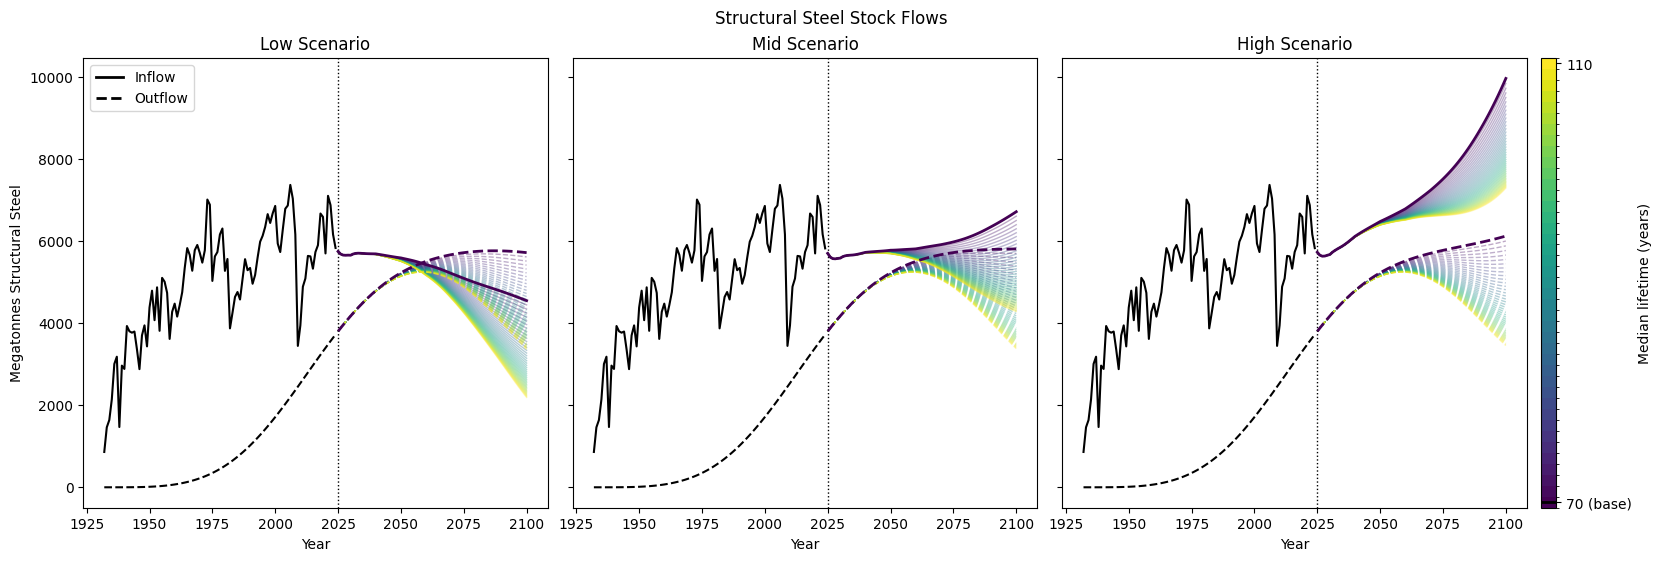

In [26]:
# ─────────────────────────────────────────────────────────────────────────────
# Plot all 3 Inflows and Outflows across all demand scenarios
# ─────────────────────────────────────────────────────────────────────────────

def _draw_panel(ax, scenario_results, inflow_series, years, title, cmap, norm,
                change_year=2024, base_lifetime=70, historical_outflow=None):
    lifetime_values = sorted(int(k.split('_')[1]) for k in scenario_results)
    mask = years > change_year

    for lifetime in lifetime_values:
        res = scenario_results[f'lifetime_{lifetime}']
        inflow = np.asarray(res['I_steel'])      # lifetime-dependent demand
        outflow = np.asarray(res['O_steel'])
        color = cmap(norm(lifetime))
        is_base = (lifetime == base_lifetime)
        alpha = 1.0 if is_base else 0.35
        lw = 2.0 if is_base else 1.0
        zorder = 10 if is_base else 2
        ax.plot(years[mask], inflow[mask], color=color, alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='-')
        ax.plot(years[mask], outflow[mask], color=color, alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='--')

    # Historical period: identical across lifetimes, so plot once in black
    hist_mask = years <= change_year
    ax.plot(years[hist_mask], np.asarray(inflow_series)[hist_mask],
            color='black', linewidth=1.5, zorder=5)
    if historical_outflow is not None:
        ax.plot(years[hist_mask], np.asarray(historical_outflow),
                color='black', linestyle='--', linewidth=1.5, zorder=5)

    ax.axvline(change_year + 1, color='black', linestyle=':', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Year')


def plot_lifetime_scenarios_panels(families, years, suptitle=None,
                                   change_year=2024, base_lifetime=70,
                                   historical_outflow=None, cmap_name='viridis'):

    all_lifetimes = sorted({int(k.split('_')[1])
                         for res, _, _ in families for k in res})

    # Discrete colormap: one color per lifetime, boundaries halfway between values
    s = np.array(all_lifetimes, dtype=float)
    if len(s) > 1:
        mids = (s[:-1] + s[1:]) / 2
        bounds = np.concatenate([[s[0] - (mids[0] - s[0])], mids,
                                 [s[-1] + (s[-1] - mids[-1])]])
    else:
        bounds = np.array([s[0] - 0.5, s[0] + 0.5])
    cmap = plt.get_cmap(cmap_name, len(all_lifetimes))
    norm = BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, len(families), figsize=(5.5 * len(families), 5.5),
                             sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)

    for ax, (res, inflow, title) in zip(axes, families):
        _draw_panel(ax, res, inflow, years, title, cmap, norm,
                    change_year=change_year, base_lifetime=base_lifetime,
                    historical_outflow=historical_outflow)

    axes[0].set_ylabel('Megatonnes Structural Steel')

    # Line-style legend on the first panel only
    legend_elements = [
        Line2D([0], [0], color='black', lw=2, label='Inflow'),
        Line2D([0], [0], color='black', lw=2, linestyle='--', label='Outflow'),
    ]
    axes[0].legend(handles=legend_elements, loc='upper left')

    # Colorbar for lifetimes, spanning all panels
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar_ticks = [70, 110]
    cbar = fig.colorbar(sm, ax=axes, ticks=cbar_ticks, spacing='proportional',
                        pad=0.01, aspect=30)
    cbar.set_label('Median lifetime (years)')
    cbar.set_ticklabels([f'{v} (base)' if v == base_lifetime else str(v)
                         for v in cbar_ticks])
    if base_lifetime in all_lifetimes:
        cbar.ax.axhline(base_lifetime, color='black', linewidth=2)
        
    if suptitle:
        fig.suptitle(suptitle)
    plt.show()
    return fig, axes


### Define Historic Steel Outflows
O_steel_full = scenario_results_mid['lifetime_70']['O_steel']
hist_mask = scenario_results_mid['lifetime_70']['dsm'].t <= 2024
O_steel_historical = O_steel_full[hist_mask]

families = [
    (scenario_results_low,  df_steel_forecast['ssp3'], 'Low Scenario'),
    (scenario_results_mid,  df_steel_forecast['ssp2'], 'Mid Scenario'),
    (scenario_results_high, df_steel_forecast['ssp4'], 'High Scenario'),
]


fig, axes = plot_lifetime_scenarios_panels(
    families, years,
    suptitle='Structural Steel Stock Flows',
    historical_outflow=O_steel_historical,
)
fig.savefig(fig_dir / 'steel_flows')

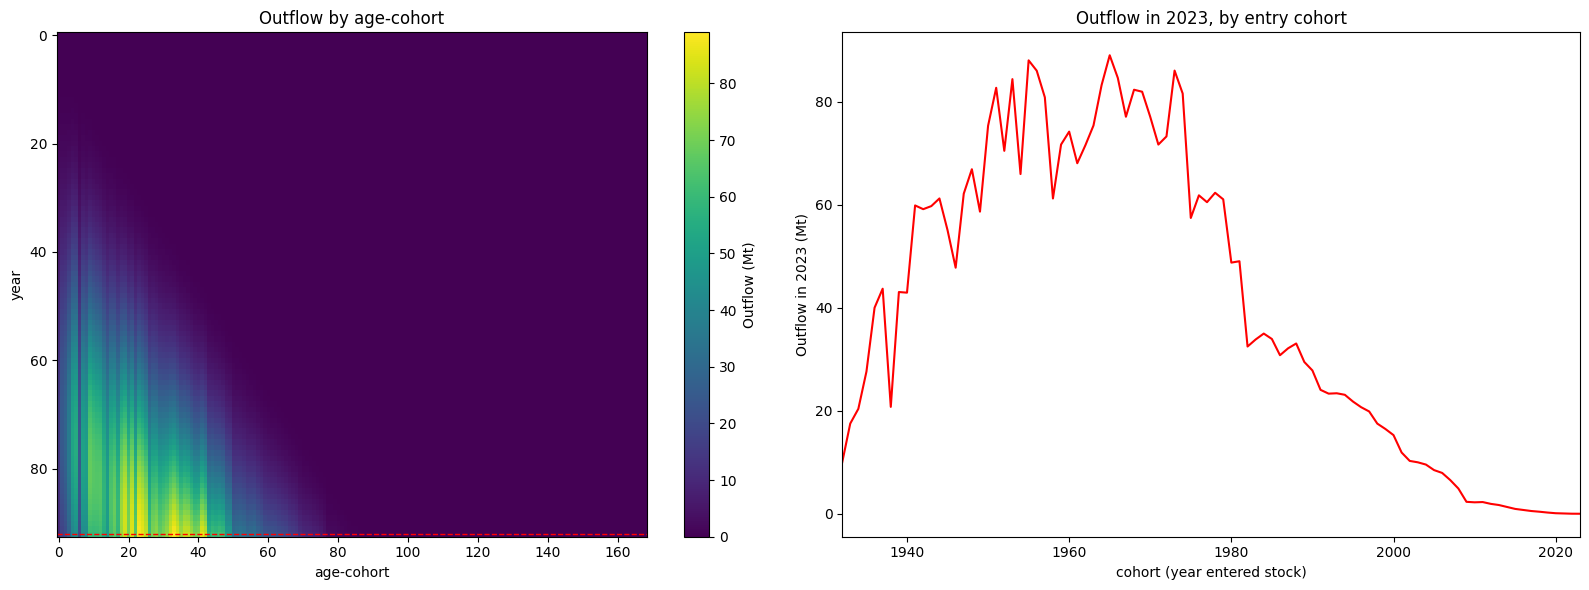

In [27]:
O_C_hist = scenario_results_mid['lifetime_70']['O_C'][hist_mask]  # shape (93, 169)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Left: heatmap  ---
im = ax1.imshow(O_C_hist, interpolation='nearest', aspect='auto', cmap='viridis')
ax1.set_xlabel('age-cohort')
ax1.set_ylabel('year')
ax1.set_title('Outflow by age-cohort')
fig.colorbar(im, ax=ax1, label='Outflow (Mt)')

last_row_idx = O_C_hist.shape[0] - 1 
ax1.axhline(last_row_idx, color='red', linestyle='--', linewidth=1)

# --- Right: single-year cohort slice ---
cohort_years = years  
outflow_2023 = O_C_hist[last_row_idx, :]

ax2.plot(cohort_years, outflow_2023, color='red', linewidth=1.5)
ax2.set_xlabel('cohort (year entered stock)')
ax2.set_ylabel('Outflow in 2023 (Mt)')
ax2.set_title('Outflow in 2023, by entry cohort')
ax2.set_xlim(cohort_years.min(), 2023)  
plt.tight_layout()
plt.show()

From here I need to calculate what percentage of outflow came from pre-1960 in 2023

### Convert to Tidy Data

In [43]:
def tidy_scenario_results(scenario_results, years, inflow_series=None):
    """
    Converts a scenario_results dict into two tidy DataFrames:
      - df_annual: one row per (median, year, variable) for 1D series
                   (Inflow, Stock, Outflow, Stock_Change)
      - df_cohort: one row per (median, year, cohort, variable) for 2D series
                   (Stock_by_cohort, Outflow_by_cohort)
    """
    annual_rows = []
    cohort_rows = []

    for scale_key, result in scenario_results.items():
        lifetime = result['lifetime_median']

        # --- 1D annual series ---
        annual_vars = {
            'Inflow': result['I_steel'],
            'Stock': result['S_steel'],
            'Outflow': result['O_steel'],
            'Stock_Change': result['DS_steel'],
        }
        if inflow_series is not None:
            annual_vars['Inflow'] = np.array(inflow_series)

        for var_name, values in annual_vars.items():
            values = np.asarray(values)
            for yr, val in zip(years, values):
                annual_rows.append({
                    'lifetime': lifetime,
                    'year': yr,
                    'variable': var_name,
                    'value': val,
                })

        # --- 2D cohort-indexed series (year x cohort) ---
        cohort_vars = {
            'Stock_by_cohort': result['stock_by_cohort'],
            'Outflow_by_cohort': result['O_C'],
        }
        for var_name, matrix in cohort_vars.items():
            matrix = np.asarray(matrix)
            for yr_idx, yr in enumerate(years):
                for cohort_idx, cohort_yr in enumerate(years):
                    val = matrix[yr_idx, cohort_idx]
                    if val == 0:
                        continue  # skip structural zeros to keep table size manageable
                    cohort_rows.append({
                        'lifetime': lifetime,
                        'year': yr,
                        'cohort': cohort_yr,
                        'variable': var_name,
                        'value': val,
                    })

    df_annual = pd.DataFrame(annual_rows)
    df_cohort = pd.DataFrame(cohort_rows)
    return df_annual, df_cohort


In [44]:
df_tidy_low, df_cohort_low = tidy_scenario_results(scenario_results_low, years)
df_tidy_mid, df_cohort_mid = tidy_scenario_results(scenario_results_mid, years)
df_tidy_high, df_cohort_high = tidy_scenario_results(scenario_results_high, years)

In [45]:
df_tidy_mid


,lifetime,year,variable,value
0,70,1932,Inflow,860.000000
1,70,1933,Inflow,1460.000000
2,70,1934,Inflow,1637.000000
3,70,1935,Inflow,2142.000000
4,70,1936,Inflow,3002.000000
...,...,...,...,...
27711,110,2096,Stock_Change,754.973836
27712,110,2097,Stock_Change,791.657316
27713,110,2098,Stock_Change,829.104062
27714,110,2099,Stock_Change,867.262941


### Percent demand Satisfied by Outflows

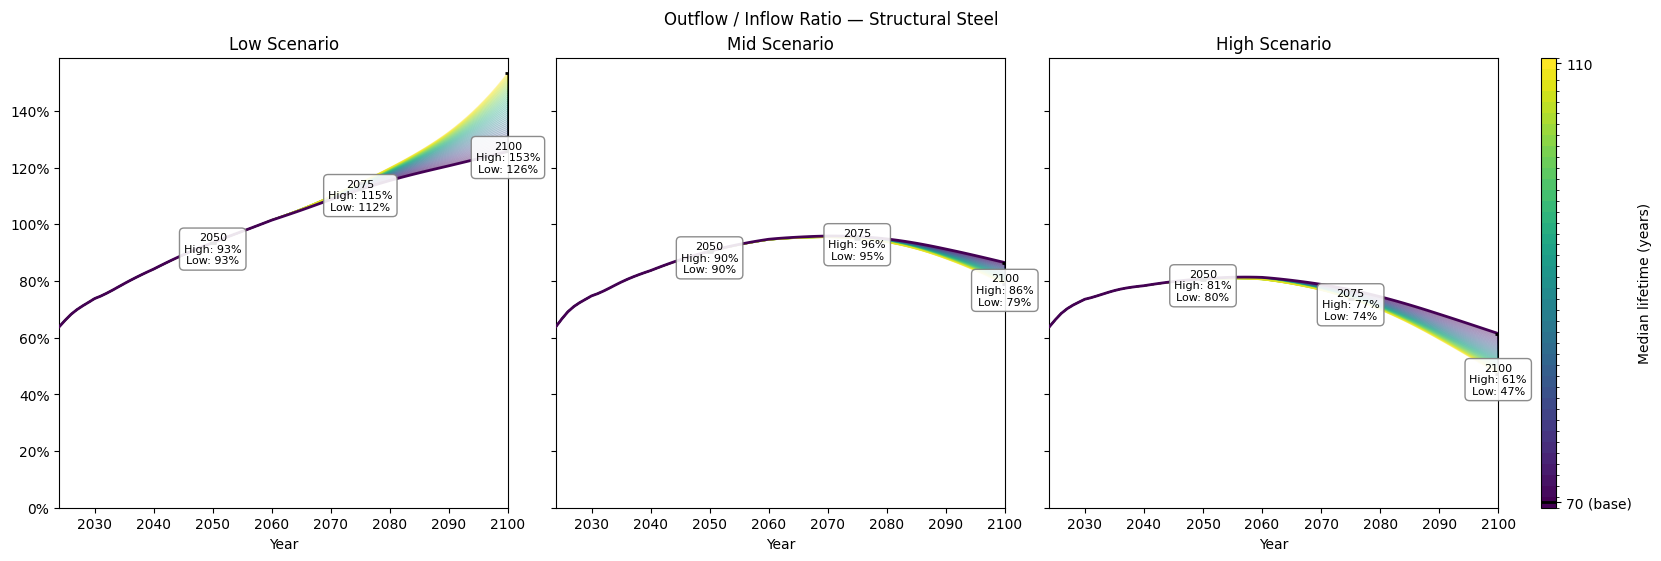

In [49]:
def compute_outflow_inflow_ratio(df_tidy, start_year=2024, end_year=2100):

    pivoted = df_tidy[df_tidy['variable'].isin(['Inflow', 'Outflow'])].pivot_table(
        index=['lifetime', 'year'], columns='variable', values='value'
    ).reset_index()

    pivoted['ratio'] = pivoted['Outflow'] / pivoted['Inflow']

    # restrict to the display window
    pivoted = pivoted[(pivoted['year'] >= start_year) & (pivoted['year'] <= end_year)]


    return pivoted

def _lifetime_cmap(all_lifetimes, cmap_name='viridis'):
    """Discrete colormap + norm with one color per lifetime."""
    s = np.array(sorted(all_lifetimes), dtype=float)
    if len(s) > 1:
        mids = (s[:-1] + s[1:]) / 2
        bounds = np.concatenate([[s[0] - (mids[0] - s[0])], mids,
                                 [s[-1] + (s[-1] - mids[-1])]])
    else:
        bounds = np.array([s[0] - 0.5, s[0] + 0.5])
    cmap = plt.get_cmap(cmap_name, len(s))
    norm = BoundaryNorm(bounds, cmap.N)
    return cmap, norm


def _draw_ratio_panel(ax, ratio_df, title, cmap, norm, base_lifetime=70,
                      annotate_years=(2050, 2075, 2100)):
    """Draw one scenario family's Outflow/Inflow ratio onto an existing axis."""
    for lifetime in sorted(ratio_df['lifetime'].unique()):
        subset = ratio_df[ratio_df['lifetime'] == lifetime].sort_values('year')
        is_base = (lifetime == base_lifetime)
        ax.plot(subset['year'], subset['ratio'] * 100,
                color=cmap(norm(lifetime)),
                alpha=1.0 if is_base else 0.4,
                linewidth=2.0 if is_base else 1.0,
                zorder=10 if is_base else 2)

    # --- annotate min/max ratio at each specified year ---
    for yr in annotate_years:
        year_slice = ratio_df[ratio_df['year'] == yr]
        if year_slice.empty:
            continue

        max_pct = year_slice['ratio'].max() * 100
        min_pct = year_slice['ratio'].min() * 100

        ax.annotate(
            f"{yr}\nHigh: {max_pct:.0f}%\nLow: {min_pct:.0f}%",
            xy=(yr, max_pct),
            xytext=(yr, min_pct - 8),
            ha='center', va='bottom', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                      edgecolor='gray', alpha=0.9),
            zorder=20,
        )
        ax.vlines(x=yr, ymin=min_pct, ymax=max_pct,
                  color='black', linewidth=2, zorder=1)
        ax.hlines(y=[min_pct, max_pct], xmin=yr - 0.5, xmax=yr + 0.5,
                  color='black', linewidth=2, zorder=15)

    ax.set_title(title)
    ax.set_xlabel('Year')


def plot_outflow_inflow_ratio_panels(families, suptitle=None, base_lifetime=70,
                                     start_year=2024, end_year=2100,
                                     annotate_years=(2050, 2075, 2100),
                                     cbar_ticks=(70, 110), cmap_name='viridis'):
    """
    families: list of (df_tidy, panel_title) tuples.
    """
    ratio_dfs = [compute_outflow_inflow_ratio(df, start_year=start_year,
                                              end_year=end_year)
                 for df, _ in families]

    # Every lifetime across all families, so colors match across panels
    all_lifetimes = sorted(set().union(*(r['lifetime'].unique() for r in ratio_dfs)))
    cmap, norm = _lifetime_cmap(all_lifetimes, cmap_name)

    fig, axes = plt.subplots(1, len(families), figsize=(5.5 * len(families), 5.5),
                             sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)

    for ax, ratio_df, (_, title) in zip(axes, ratio_dfs, families):
        _draw_ratio_panel(ax, ratio_df, title, cmap, norm,
                          base_lifetime=base_lifetime, annotate_years=annotate_years)
        ax.set_xlim(start_year, end_year)

    # Shared y-axis: formatting and lower limit apply to all panels
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
    axes[0].set_ylim(bottom=0)
    # axes[0].set_ylabel('Percent of Inflows met by Outflows')

    # Colorbar for lifetimes, labeled only at the chosen ticks
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = fig.colorbar(sm, ax=axes, ticks=list(cbar_ticks),
                        spacing='proportional', pad=0.01, aspect=30)
    cbar.set_label('Median lifetime (years)')
    cbar.set_ticklabels([f'{v} (base)' if v == base_lifetime else str(v)
                         for v in cbar_ticks])
    if base_lifetime in all_lifetimes:
        cbar.ax.axhline(base_lifetime, color='black', linewidth=2)

    if suptitle:
        fig.suptitle(suptitle)
    plt.show()
    return fig, axes


families = [
    (df_tidy_low,  'Low Scenario'),
    (df_tidy_mid,  'Mid Scenario'),
    (df_tidy_high, 'High Scenario'),
]

fig, axes = plot_outflow_inflow_ratio_panels(
    families, suptitle='Outflow / Inflow Ratio — Structural Steel'
)
fig.savefig(fig_dir / 'flow_ratios.png', dpi=300, bbox_inches='tight')

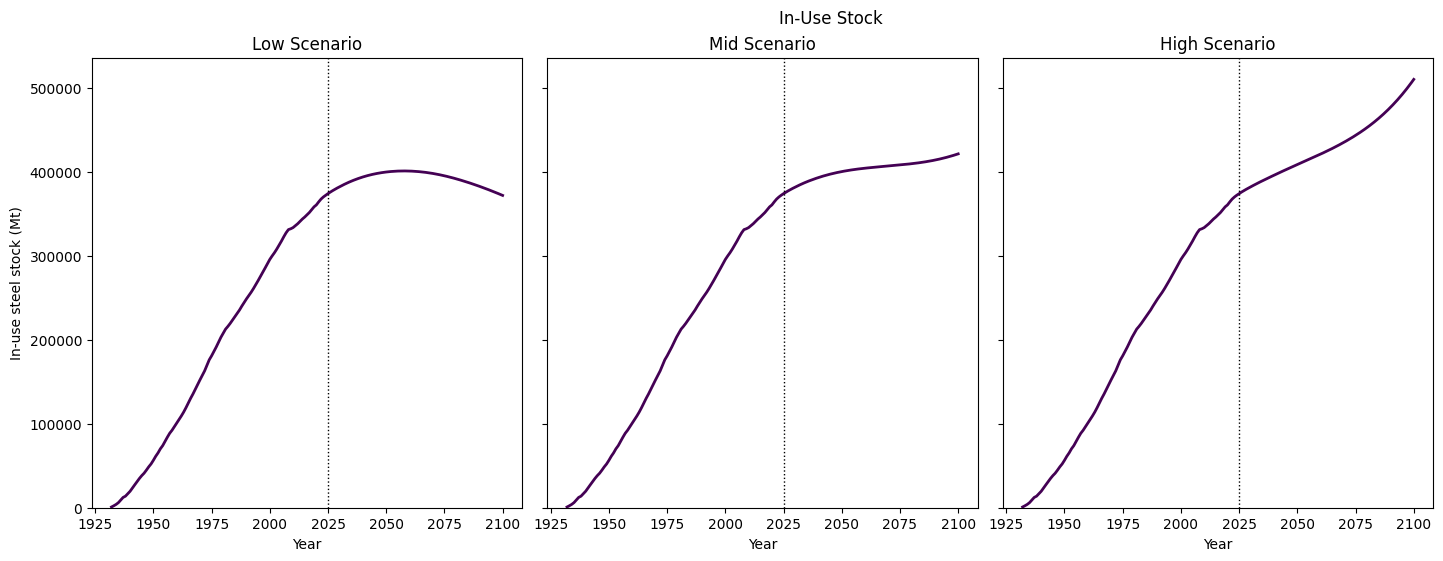

In [50]:
def inflow_driven_stock(inflow_series, years, base_shape=3.5, base_lifetime=70,
                        change_year=2024, medians=range(70, 111)):
    
    n = len(years)
    shape_array = np.full(n, base_shape)
    base_scale = median_to_scale(base_lifetime, base_shape)
    inflow = np.array(inflow_series, dtype=float)

    stocks = {}
    for lt in lifetimes:
        new_scale = median_to_scale(lt, base_shape)
        scale_array = np.where(years <= change_year, base_scale, new_scale)
        m = dsm.DynamicStockModel(t=years, i=inflow,
                lt={'Type': 'Weibull', 'Shape': shape_array, 'Scale': scale_array})
        m.compute_s_c_inflow_driven()
        stocks[lt] = m.compute_stock_total()
    return stocks


stock_families = [
    (scenario_results_low,  'Low Scenario'),
    (scenario_results_mid,  'Mid Scenario'),
    (scenario_results_high, 'High Scenario'),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5), sharey=True, constrained_layout=True)
for ax, (res, title) in zip(axes, stock_families):
    ax.plot(years, res['lifetime_70']['S_steel'], color='#440154', linewidth=2)
    ax.axvline(2025, color='black', linestyle=':', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Year')

axes[0].set_ylabel('In-use steel stock (Mt)')
axes[0].set_ylim(bottom=0)

cmap, norm = _lifetime_cmap(list(range(70, 111)))
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, ticks=[70, 110], spacing='proportional',
                    pad=0.01, aspect=30)
cbar.set_label('Median lifetime (years)')
cbar.ax.set_visible(False)

fig.suptitle('In-Use Stock')
plt.show()

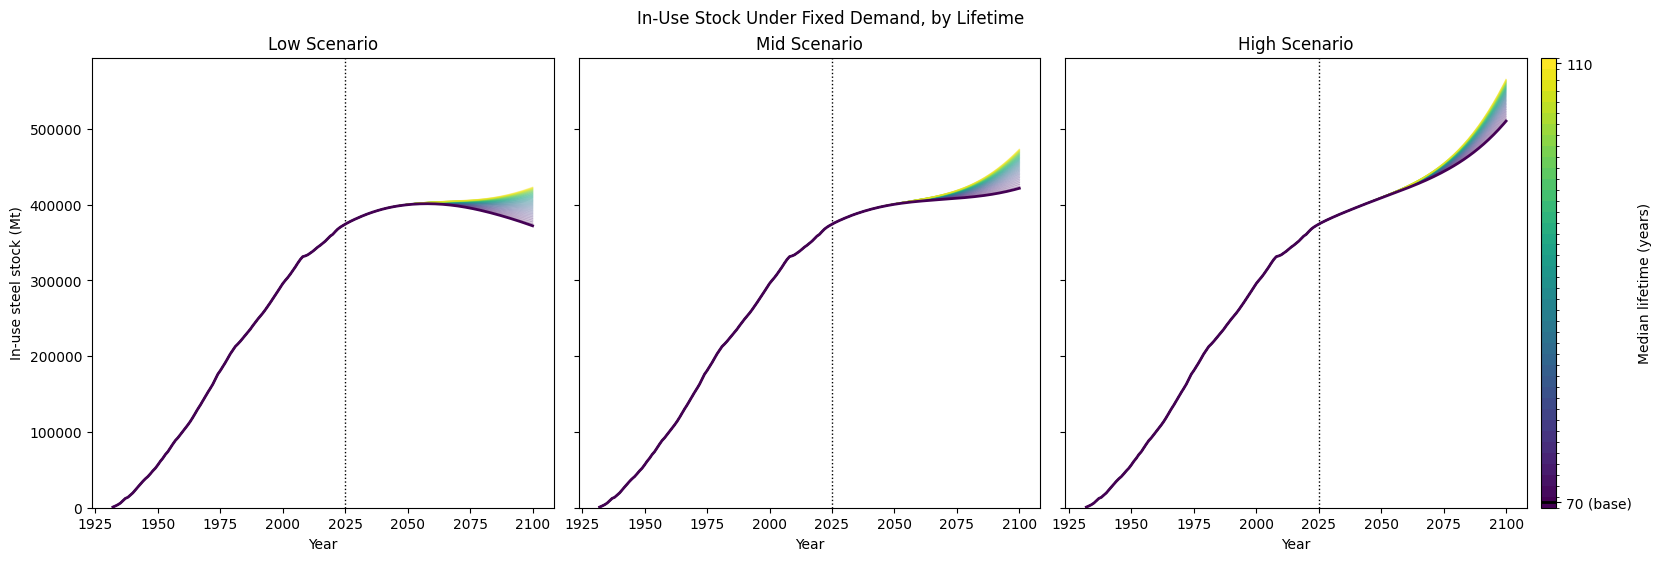

In [51]:
def inflow_driven_stock(inflow_series, years, base_shape=3.5, base_lifetime=70,
                        change_year=2024, lifetimes=range(70, 111)):
    """Stock under fixed (regression) demand, longer lifetime for new cohorts only."""
    n = len(years)
    shape_array = np.full(n, base_shape)
    base_scale = median_to_scale(base_lifetime, base_shape)
    inflow = np.array(inflow_series, dtype=float)

    stocks = {}
    for lt in lifetimes:
        new_scale = median_to_scale(lt, base_shape)
        scale_array = np.where(years <= change_year, base_scale, new_scale)
        m = dsm.DynamicStockModel(t=years, i=inflow,
                lt={'Type': 'Weibull', 'Shape': shape_array, 'Scale': scale_array})
        m.compute_s_c_inflow_driven()
        stocks[lt] = m.compute_stock_total()
    return stocks


stock_families = [
    (inflow_driven_stock(df_steel_forecast['ssp3'], years), 'Low Scenario'),
    (inflow_driven_stock(df_steel_forecast['ssp2'], years), 'Mid Scenario'),
    (inflow_driven_stock(df_steel_forecast['ssp4'], years), 'High Scenario'),
]

all_lifetimes = list(range(70, 111))
cmap, norm = _lifetime_cmap(all_lifetimes)
base_lifetime = 70

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5), sharey=True, constrained_layout=True)
for ax, (stocks, title) in zip(axes, stock_families):
    for lt, S in stocks.items():
        is_base = (lt == base_lifetime)
        ax.plot(years, S, color=cmap(norm(lt)),
                alpha=1.0 if is_base else 0.35,
                linewidth=2.0 if is_base else 1.0,
                zorder=10 if is_base else 2)
    ax.axvline(2025, color='black', linestyle=':', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Year')

axes[0].set_ylabel('In-use steel stock (Mt)')
axes[0].set_ylim(bottom=0)

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, ticks=[70, 110], spacing='proportional',
                    pad=0.01, aspect=30)
cbar.set_label('Median lifetime (years)')
cbar.set_ticklabels(['70 (base)', '110'])
cbar.ax.axhline(base_lifetime, color='black', linewidth=2)

fig.suptitle('In-Use Stock Under Fixed Demand, by Lifetime')
plt.show()

## Scenario Analysis of Reuse Rates and Green Steel adoption

In [54]:
# ─────────────────────────────────────────────────────────────────────────────
# Make grid of technology adoption
# ─────────────────────────────────────────────────────────────────────────────

# Fixed, hand-adjustable curve-shape parameters — not sampled
G_reuse, M_reuse = 0.2, 2060   # adoption speed / inflection year for reuse
G_green, M_green = 0.2, 2060   # adoption speed / inflection year for green steel

def generate_grid_ceilings(step=10):
    """
    Replaces QMC sampling with a regular grid of (B_reuse, B_green) ceilings,
    each ranging 0-100% in `step`-sized increments. A fixed at 0; G, M fixed constants.
    """
    ceilings = np.arange(0, 100 + step, step) / 100  # 0.0, 0.1, ..., 1.0
    combos = list(itertools.product(ceilings, ceilings))

    df_params = pd.DataFrame(combos, columns=['B_reuse', 'B_green'])
    df_params['A_reuse'] = 0.0
    df_params['A_green'] = 0.0
    df_params['G_reuse'] = G_reuse
    df_params['M_reuse'] = M_reuse
    df_params['G_green'] = G_green
    df_params['M_green'] = M_green
    df_params['draw_id'] = np.arange(len(df_params))
    return df_params


param_df = generate_grid_ceilings(step=10)
print(param_df.shape)  # (121, 7)
param_df.head()

(121, 9)


,B_reuse,B_green,A_reuse,A_green,G_reuse,M_reuse,G_green,M_green,draw_id
0,0.0,0.0,0.0,0.0,0.2,2060,0.2,2060,0
1,0.0,0.1,0.0,0.0,0.2,2060,0.2,2060,1
2,0.0,0.2,0.0,0.0,0.2,2060,0.2,2060,2
3,0.0,0.3,0.0,0.0,0.2,2060,0.2,2060,3
4,0.0,0.4,0.0,0.0,0.2,2060,0.2,2060,4


In [55]:
### Define Scenarios

def logistic_curve(t, A, B, G, M):
    return A + (B - A) / (1 + np.exp(-G * (t - M)))

def run_qmc_scenarios(scenario_results, years, param_df,
                      change_year=2024, end_year=2100):
    """
    For each lifetime in scenario_results, applies all parameter draws
    (B_reuse, B_green ceilings; fixed A/G/M) to compute:
      - reuse_rate(t) and reused_outflow(t)
      - production_demand(t) = max(demand_total(t) - reused_outflow(t), 0)
      - green_share(t) and the green/conventional split of production_demand
    demand_total is the lifetime-dependent inflow (I_steel) from the stock-driven model.
    """
    years = np.array(years)
    mask = (years >= change_year) & (years <= end_year)
    t = years[mask]

    A_r = param_df['A_reuse'].values[:, None]
    B_r = param_df['B_reuse'].values[:, None]
    G_r = param_df['G_reuse'].values[:, None]
    M_r = param_df['M_reuse'].values[:, None]
    A_g = param_df['A_green'].values[:, None]
    B_g = param_df['B_green'].values[:, None]
    G_g = param_df['G_green'].values[:, None]
    M_g = param_df['M_green'].values[:, None]

    draw_ids = param_df['draw_id'].values
    n_draws = len(param_df)
    n_years = len(t)

    reuse_rate = logistic_curve(t[None, :], A_r, B_r, G_r, M_r)
    green_share = np.clip(logistic_curve(t[None, :], A_g, B_g, G_g, M_g), 0, 1)

    frames = []
    for lifetime_key, result in scenario_results.items():
        lifetime = result['lifetime_median']
        demand_total = np.array(result['I_steel'])[mask]    # lifetime-dependent demand
        outflow_total = np.array(result['O_steel'])[mask]

        reused_outflow = reuse_rate * outflow_total[None, :]
        production_demand = np.maximum(demand_total[None, :] - reused_outflow, 0)
        green_production = green_share * production_demand
        conventional_production = (1 - green_share) * production_demand

        frames.append(pd.DataFrame({
            'lifetime': lifetime,
            'draw_id': np.repeat(draw_ids, n_years),
            'year': np.tile(t, n_draws),
            'demand_total': np.tile(demand_total, n_draws),
            'reuse_rate': reuse_rate.ravel(),
            'reused_outflow': reused_outflow.ravel(),
            'production_demand': production_demand.ravel(),
            'green_share': green_share.ravel(),
            'green_production': green_production.ravel(),
            'conventional_production': conventional_production.ravel(),
        }))

    return pd.concat(frames, ignore_index=True)

In [56]:
df_qmc_low  = run_qmc_scenarios(scenario_results_low, years, param_df)
df_qmc_mid  = run_qmc_scenarios(scenario_results_mid, years, param_df)
df_qmc_high = run_qmc_scenarios(scenario_results_high, years, param_df)

## Emissions Analysis

Defining emissions factors here

In [57]:
conventional_co2 = (.898 + ((0.026+0.0824)*1.0771))*1e6
reuse_co2 = ((0.0262+0.0824)*1.0771)*1e6
green_co2 = conventional_co2 * 0.33

In [58]:
print(conventional_co2 / 1e6)
print(reuse_co2 / 1e6)
print(green_co2 / 1e6)

1.01475764
0.11697305999999999
0.33487002120000003


In [59]:
## Energy Coefficients
conventional_mj = 1730+12800 + ((1.11 + 15 + 503 + 1460) * 1.0771)
reuse_mj = ((1.11 + 15 + 503 + 1460) * 1.0771)
green_mj = conventional_mj * 1.13

In [60]:
print(conventional_mj)
print(reuse_mj)
print(green_mj)

16661.699381
2131.699381
18827.720300529996


Adding emissions to the dataframes

In [61]:
def add_carbon_emissions(df_qmc, conventional_co2, reuse_co2, green_co2):
    df_qmc = df_qmc.copy()
    reuse_used = df_qmc['demand_total'] - df_qmc['production_demand']   # = min(reused, demand)
    df_qmc['reuse_used'] = reuse_used
    df_qmc['carbon_emissions'] = (
        df_qmc['conventional_production'] * conventional_co2
        + df_qmc['green_production'] * green_co2
        + reuse_used * reuse_co2
    )
    return df_qmc

In [62]:
def add_energy_usage(df_qmc, conventional_mj, reuse_mj, green_mj):
    df_qmc = df_qmc.copy()
    reuse_used = df_qmc['demand_total'] - df_qmc['production_demand']   # = min(reused, demand)
    df_qmc['reuse_used'] = reuse_used
    df_qmc['energy_usage'] = (
        df_qmc['conventional_production'] * conventional_mj
        + df_qmc['green_production'] * green_mj
        + reuse_used * reuse_mj
    )
    return df_qmc


In [63]:
df_qmc_low  = add_carbon_emissions(df_qmc_low,  conventional_co2, reuse_co2, green_co2)
df_qmc_mid  = add_carbon_emissions(df_qmc_mid,  conventional_co2, reuse_co2, green_co2)
df_qmc_high = add_carbon_emissions(df_qmc_high, conventional_co2, reuse_co2, green_co2)

In [64]:
df_qmc_low  = add_energy_usage(df_qmc_low,  conventional_mj, reuse_mj, green_mj)
df_qmc_mid  = add_energy_usage(df_qmc_mid,  conventional_mj, reuse_mj, green_mj)
df_qmc_high = add_energy_usage(df_qmc_high, conventional_mj, reuse_mj, green_mj)

In [66]:
# ─────────────────────────────────────────────────────────────────────────────
# Defining Industry target (85% reduction in carbon emissiosn by 2100)
# ─────────────────────────────────────────────────────────────────────────────
demand = df_steel_forecast['ssp2'].loc[2024:2100]
years = demand.index.astype(int)
 

START_YEAR = 2024
END_YEAR = 2100
TOTAL_REDUCTION = 0.85
 
end_factor = conventional_co2 * (1 - TOTAL_REDUCTION)
n_years_total = END_YEAR - START_YEAR
 
annual_decline = (conventional_co2 - end_factor) / n_years_total
 
emissions_factor = pd.Series(
    conventional_co2 - annual_decline * (years - START_YEAR),
    index=years,
)
 

total_emissions = emissions_factor * demand

industry_target = pd.DataFrame({
    'demand_tons': demand,
    'emissions_factor_tco2_per_ton': emissions_factor,
    'total_emissions_co2_MT': total_emissions,
}, index=years)
industry_target.index.name = 'year'

 

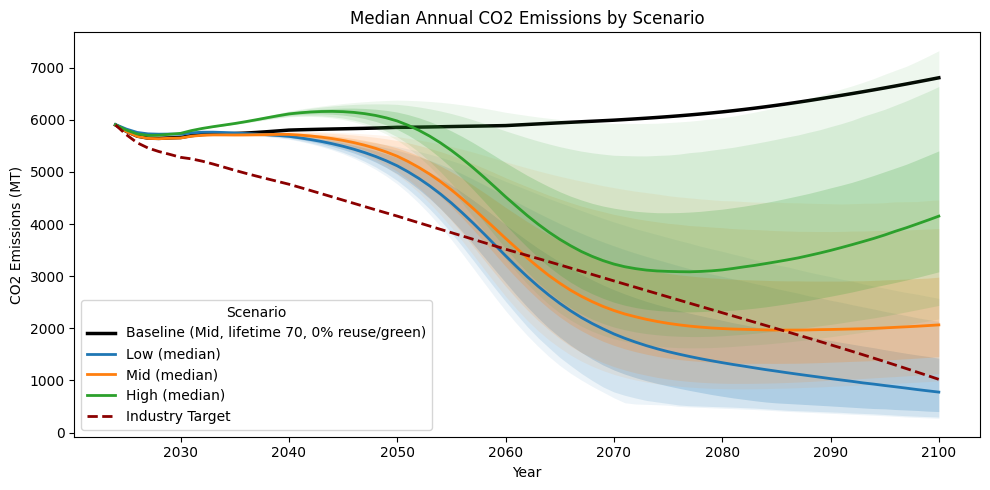

In [69]:
# ─────────────────────────────────────────────────────────────────────────────
# Plot annual emissions across scenarios 
# ─────────────────────────────────────────────────────────────────────────────
def get_baseline_emissions(df_qmc_mid, param_df, baseline_lifetime=70):
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['lifetime'] == baseline_lifetime) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')

    return baseline_rows.set_index('year')['carbon_emissions']


def emissions_summary_by_year(df_qmc, quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    grouped = df_qmc.groupby('year')['carbon_emissions']
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                industry_target=None,
                                baseline_lifetime=70,
                                title='Median Annual CO2 Emissions by Scenario'):
    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low, quantiles) / 1e6,
        'Mid':  emissions_summary_by_year(df_qmc_mid, quantiles) / 1e6,
        'High': emissions_summary_by_year(df_qmc_high, quantiles) / 1e6,
    }

    baseline_series = get_baseline_emissions(df_qmc_mid, param_df, baseline_lifetime=baseline_lifetime)

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(baseline_series.index, baseline_series.values / 1e6,
            color='black', linewidth=2.5,
            label=f'Baseline (Mid, lifetime {baseline_lifetime}, 0% reuse/green)', zorder=1)

    for label, summary in summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(summary.index, summary[lower_q], summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    if industry_target is not None:
        target_series = industry_target.set_index('year')['total_emissions_co2_MT'] / 1e6 \
            if 'year' in industry_target.columns else industry_target['total_emissions_co2_MT'] / 1e6
        ax.plot(target_series.index, target_series.values,
                color='darkred', linewidth=2, linestyle='--',
                label='Industry Target', zorder=8)

    ax.set_xlabel('Year')
    ax.set_ylabel('CO2 Emissions (MT)')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='lower left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                     industry_target=industry_target)
fig.savefig(fig_dir / 'median_annual_carbon_emissions.png', dpi = 300, bbox_inches='tight')

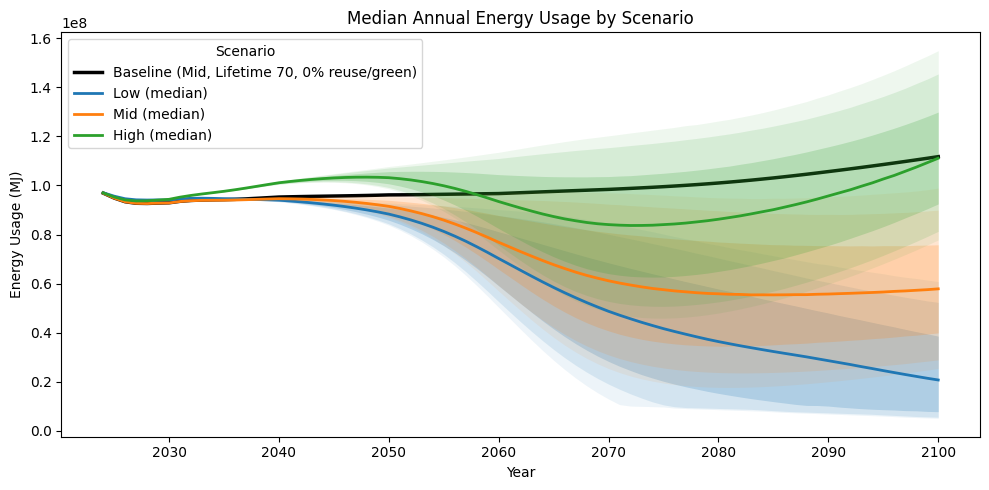

In [70]:
def get_baseline_energy(df_qmc_mid, param_df, baseline_lifetime=70, energy_col='energy_usage'):
    """
    Pulls the annual energy usage trajectory for the Mid scenario,
    at baseline_scale, with 0% reuse and 0% green steel ceilings.
    """
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['lifetime'] == baseline_lifetime) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')

    return baseline_rows.set_index('year')[energy_col]


def energy_summary_by_year(df_qmc, energy_col='energy_usage', quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    """
    Median plus a set of quantiles per year, across all scales and draws —
    used to build density-style shaded bands.
    """
    grouped = df_qmc.groupby('year')[energy_col]
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def plot_energy_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                             energy_col='energy_usage',
                             baseline_lifetime=70,
                             title='Median Annual Energy Usage by Scenario'):
    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  energy_summary_by_year(df_qmc_low, energy_col=energy_col, quantiles=quantiles),
        'Mid':  energy_summary_by_year(df_qmc_mid, energy_col=energy_col, quantiles=quantiles),
        'High': energy_summary_by_year(df_qmc_high, energy_col=energy_col, quantiles=quantiles),
    }

    baseline_series = get_baseline_energy(df_qmc_mid, param_df, baseline_lifetime=baseline_lifetime,
                                            energy_col=energy_col)

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline: Mid scenario, scale 70, 0% reuse, 0% green steel
    ax.plot(baseline_series.index, baseline_series.values,
            color='black', linewidth=2.5,
            label=f'Baseline (Mid, Lifetime {baseline_lifetime}, 0% reuse/green)', zorder=1)

    for label, summary in summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(summary.index, summary[lower_q], summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    ax.set_xlabel('Year')
    ax.set_ylabel('Energy Usage (MJ)')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_energy_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df)
fig.savefig(fig_dir / 'median_annual_energy_usage.png', dpi = 300, bbox_inches='tight')

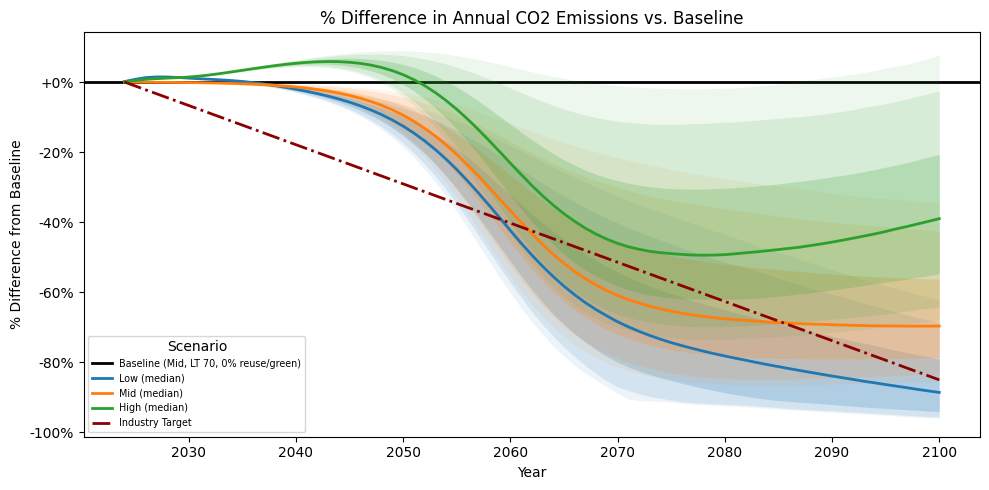

In [71]:
def emissions_summary_by_year(df_qmc, quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    """
    Median plus a set of quantiles per year, across all scales and draws —
    used to build density-style shaded bands.
    """
    grouped = df_qmc.groupby('year')['carbon_emissions']
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def compute_pct_diff_from_baseline(summary, baseline_series):
    """
    Converts an emissions summary (median + quantile columns by year) into
    % difference from a baseline series (indexed by year).
    """
    aligned_baseline = baseline_series.reindex(summary.index)
    pct_diff = pd.DataFrame(index=summary.index)
    for col in summary.columns:
        pct_diff[col] = (summary[col] - aligned_baseline) / aligned_baseline * 100
    return pct_diff


def compute_pct_diff_series_from_baseline(series, baseline_series):
    """
    Same logic as compute_pct_diff_from_baseline, but for a single series
    (not a summary) — used for reference lines like industry targets or
    external emissions estimates.
    """
    aligned_baseline = baseline_series.reindex(series.index)
    return (series - aligned_baseline) / aligned_baseline * 100


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                industry_target=None, arehart=None,
                                baseline_lifetime=70,
                                title='% Difference in Annual CO2 Emissions vs. Baseline'):
    # identify the baseline draw_id: the grid point where B_reuse=0 and B_green=0
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['lifetime'] == baseline_lifetime) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')
    baseline_series = baseline_rows.set_index('year')['carbon_emissions']

    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low, quantiles),
        'Mid':  emissions_summary_by_year(df_qmc_mid, quantiles),
        'High': emissions_summary_by_year(df_qmc_high, quantiles),
    }

    pct_summaries = {label: compute_pct_diff_from_baseline(s, baseline_series)
                      for label, s in summaries.items()}

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline itself: flat 0% line, in black
    ax.axhline(0, color='black', linewidth=2, label='Baseline (Mid, LT 70, 0% reuse/green)', zorder=1)

    for label, pct_summary in pct_summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(pct_summary.index, pct_summary[lower_q], pct_summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(pct_summary.index, pct_summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    # --- industry target reference line ---
    if industry_target is not None:
        target_series = industry_target.set_index('year')['total_emissions_co2_MT'] \
            if 'year' in industry_target.columns else industry_target['total_emissions_co2_MT']
        pct_target = compute_pct_diff_series_from_baseline(target_series, baseline_series)
        ax.plot(pct_target.index, pct_target.values, label='Industry Target',
                color='darkred', linewidth=2, linestyle='-.', zorder=15)

    ax.set_xlabel('Year')
    ax.set_ylabel('% Difference from Baseline')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:+.0f}%'))
    ax.legend(title='Scenario', loc='lower left', fontsize="x-small")

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(
    df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
    industry_target=industry_target
)
fig.savefig(fig_dir / 'relative_annual_carbon_emissions.png', dpi = 300, bbox_inches='tight')

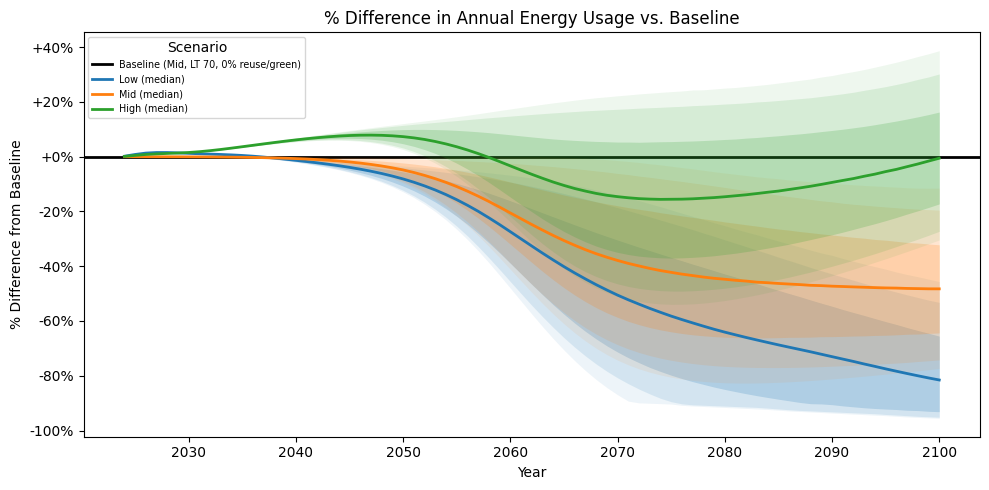

In [72]:
def compute_pct_diff_from_baseline(summary, baseline_series):
    """
    Converts a summary (median + quantile columns by year) into % difference
    from a baseline series (indexed by year). Works for any metric.
    """
    aligned_baseline = baseline_series.reindex(summary.index)
    pct_diff = pd.DataFrame(index=summary.index)
    for col in summary.columns:
        pct_diff[col] = (summary[col] - aligned_baseline) / aligned_baseline * 100
    return pct_diff


def plot_energy_pct_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                 energy_col='energy_usage',
                                 baseline_lifetime=70,
                                 title='% Difference in Annual Energy Usage vs. Baseline'):
    baseline_series = get_baseline_energy(df_qmc_mid, param_df, baseline_lifetime=baseline_lifetime,
                                            energy_col=energy_col)

    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  energy_summary_by_year(df_qmc_low, energy_col=energy_col, quantiles=quantiles),
        'Mid':  energy_summary_by_year(df_qmc_mid, energy_col=energy_col, quantiles=quantiles),
        'High': energy_summary_by_year(df_qmc_high, energy_col=energy_col, quantiles=quantiles),
    }

    pct_summaries = {label: compute_pct_diff_from_baseline(s, baseline_series)
                      for label, s in summaries.items()}

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline itself: flat 0% line, in black
    ax.axhline(0, color='black', linewidth=2, label=f'Baseline (Mid, LT {baseline_lifetime}, 0% reuse/green)', zorder=1)

    for label, pct_summary in pct_summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(pct_summary.index, pct_summary[lower_q], pct_summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(pct_summary.index, pct_summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    ax.set_xlabel('Year')
    ax.set_ylabel('% Difference from Baseline')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:+.0f}%'))
    ax.legend(title='Scenario', loc='upper left', fontsize='x-small')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_energy_pct_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df)
fig.savefig(fig_dir / 'relative_annual_energy_usage.png', dpi = 300, bbox_inches='tight')

In [77]:
### Cumulative Emissions

def summarize_lifetime_emissions(df_qmc, param_df, scenario_label):
    """
    Collapses a QMC results DataFrame (year-level) into one row per
    (scale, draw_id) with cumulative lifetime emissions, joined against
    that draw's reuse/green ceiling parameters.
    """
    cumulative = (
        df_qmc.groupby(['lifetime', 'draw_id'])['carbon_emissions']
        .sum()
        .reset_index()
        .rename(columns={'carbon_emissions': 'cumulative_emissions'})
    )

    # bring in B_reuse / B_green (the ceilings) for each draw_id
    cumulative = cumulative.merge(
        param_df[['draw_id', 'B_reuse', 'B_green']],
        on='draw_id',
        how='left'
    )

    cumulative['scenario'] = scenario_label
    return cumulative

In [78]:
df_lifetime_low  = summarize_lifetime_emissions(df_qmc_low,  param_df, 'Low')
df_lifetime_mid  = summarize_lifetime_emissions(df_qmc_mid,  param_df, 'Mid')
df_lifetime_high = summarize_lifetime_emissions(df_qmc_high, param_df, 'High')

df_lifetime_emissions = pd.concat(
    [df_lifetime_low, df_lifetime_mid, df_lifetime_high],
    ignore_index=True
)

print(df_lifetime_emissions.shape)  # should be (63000, 6)
df_lifetime_emissions.head()

(14883, 6)


,lifetime,draw_id,cumulative_emissions,B_reuse,B_green,scenario
0,70,0,4.129988e+11,0.0,0.0,Low
1,70,1,3.992364e+11,0.0,0.1,Low
2,70,2,3.854739e+11,0.0,0.2,Low
3,70,3,3.717114e+11,0.0,0.3,Low
4,70,4,3.579490e+11,0.0,0.4,Low


In [79]:
def summarize_lifetime_energy(df_qmc, param_df, scenario_label, energy_col='energy_usage'):
    """
    Collapses a QMC results DataFrame (year-level) into one row per
    (scale, draw_id) with cumulative lifetime electricity usage, joined
    against that draw's reuse/green ceiling parameters.
    """
    cumulative = (
        df_qmc.groupby(['lifetime', 'draw_id'])[energy_col]
        .sum()
        .reset_index()
        .rename(columns={energy_col: 'cumulative_energy'})
    )

    cumulative = cumulative.merge(
        param_df[['draw_id', 'B_reuse', 'B_green']],
        on='draw_id',
        how='left'
    )

    cumulative['scenario'] = scenario_label
    return cumulative


df_lifetime_energy_low  = summarize_lifetime_energy(df_qmc_low,  param_df, 'Low')
df_lifetime_energy_mid  = summarize_lifetime_energy(df_qmc_mid,  param_df, 'Mid')
df_lifetime_energy_high = summarize_lifetime_energy(df_qmc_high, param_df, 'High')

df_lifetime_energy = pd.concat(
    [df_lifetime_energy_low, df_lifetime_energy_mid, df_lifetime_energy_high],
    ignore_index=True
)

print(df_lifetime_energy.shape)

(14883, 6)


C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\3661475239.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


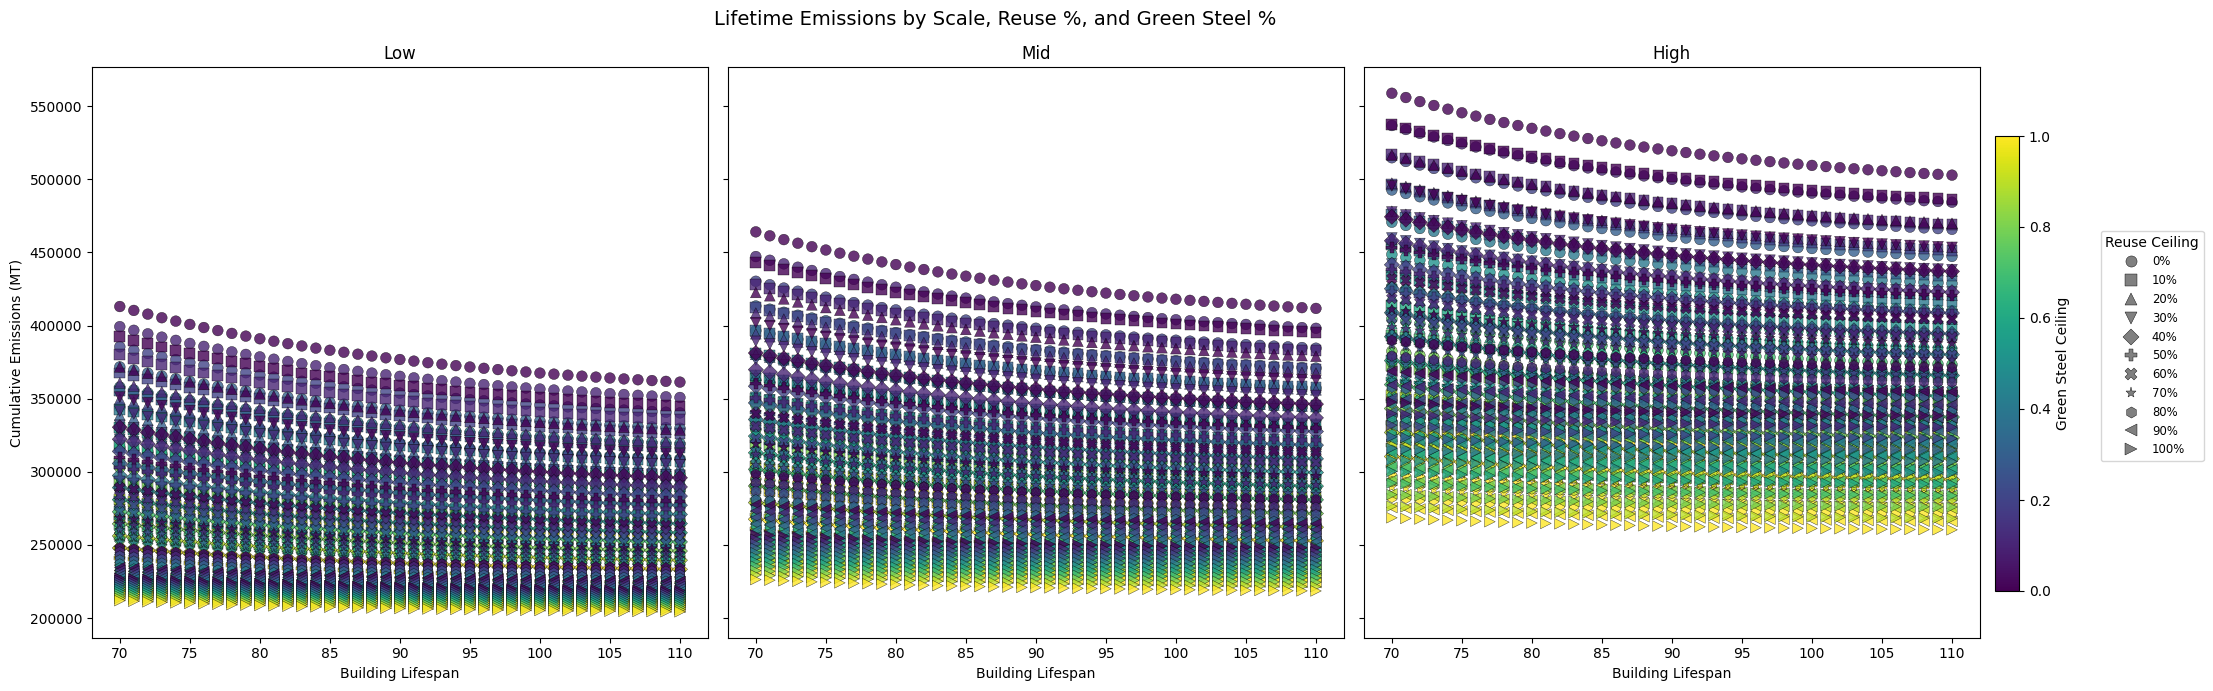

C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\3661475239.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(fig_dir / 'carbon_sensitivity.png', dpi = 300, bbox_inches='tight')


In [86]:
## Senstitivty analysis
def plot_scale_vs_emissions_grid(df_lifetime, title=None,
                                   x_col='lifetime', y_col='cumulative_emissions',
                                   shape_col='B_reuse', color_col='B_green',
                                   cmap='viridis', figsize=(20, 7)):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime emissions (MT), marker shape = reuse %, color = green steel %.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MT'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    # shared y-axis range across all three panels for fair comparison
    y_min, y_max = df_lifetime['y_MT'].min(), df_lifetime['y_MT'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        for reuse_val in reuse_levels:
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MT'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=0.8,
                edgecolors='black',
                linewidths=0.3,
            )

        ax.set_xlabel('Building Lifespan')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Emissions (MT)')

    fig.suptitle(title or 'Lifetime Emissions by Scale, Reuse %, and Green Steel %', fontsize=14)

    # reserve space on the right for shared legends
    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    # shared colorbar for green steel %
    cbar_ax = fig.add_axes([1, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax,)
    cbar.set_label('Green Steel Ceiling')

    # shared shape legend for reuse %
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in reuse_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in reuse_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_emissions_grid(df_lifetime_emissions)
fig.savefig(fig_dir / 'carbon_sensitivity.png', dpi = 300, bbox_inches='tight')

C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\2029148398.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


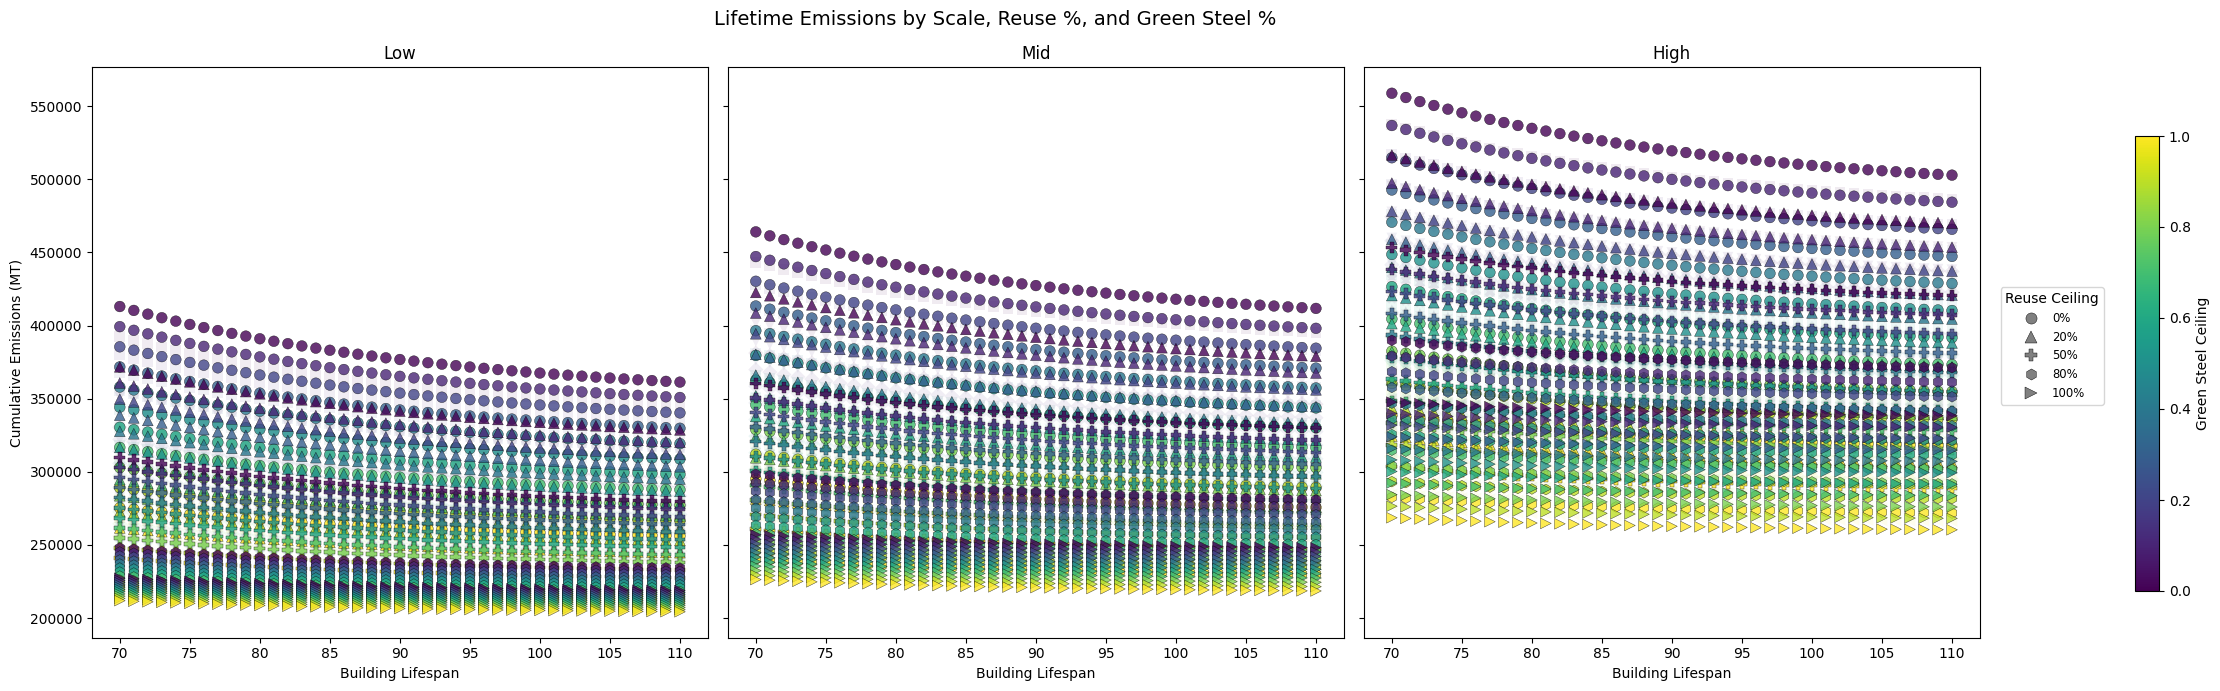

C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\2029148398.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(fig_dir / 'carbon_sensitivity_v2.png', dpi = 300, bbox_inches='tight')


In [87]:
def plot_scale_vs_emissions_grid(df_lifetime, title=None,
                                   x_col='lifetime', y_col='cumulative_emissions',
                                   shape_col='B_reuse', color_col='B_green',
                                   cmap='viridis', figsize=(20, 7),
                                   highlight_reuse=(0.0, 0.2, 0.5, 0.8, 1.0),
                                   highlight_alpha=0.8, dim_alpha=0.08):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime emissions (MT), marker shape = reuse %, color = green steel %.
    Only reuse levels in `highlight_reuse` are shown fully opaque; all others are faded.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MT'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    # tolerance-based match against highlight_reuse, to avoid float equality issues
    highlight_set = set(np.round(highlight_reuse, 6))

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    y_min, y_max = df_lifetime['y_MT'].min(), df_lifetime['y_MT'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        # plot dim (non-highlighted) points first, so highlighted ones draw on top
        for reuse_val in reuse_levels:
            is_highlighted = round(reuse_val, 6) in highlight_set
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MT'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=highlight_alpha if is_highlighted else dim_alpha,
                edgecolors='black',
                linewidths=0.3 if is_highlighted else 0,
                zorder=5 if is_highlighted else 1,
            )

        ax.set_xlabel('Building Lifespan')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Emissions (MT)')

    fig.suptitle(title or 'Lifetime Emissions by Scale, Reuse %, and Green Steel %', fontsize=14)

    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    cbar_ax = fig.add_axes([1.07, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Green Steel Ceiling')

    # shape legend only for highlighted reuse levels (the ones actually visible)
    highlighted_levels = [lvl for lvl in reuse_levels if round(lvl, 6) in highlight_set]
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in highlighted_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in highlighted_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_emissions_grid(df_lifetime_emissions)
fig.savefig(fig_dir / 'carbon_sensitivity_v2.png', dpi = 300, bbox_inches='tight')

C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\2586498136.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


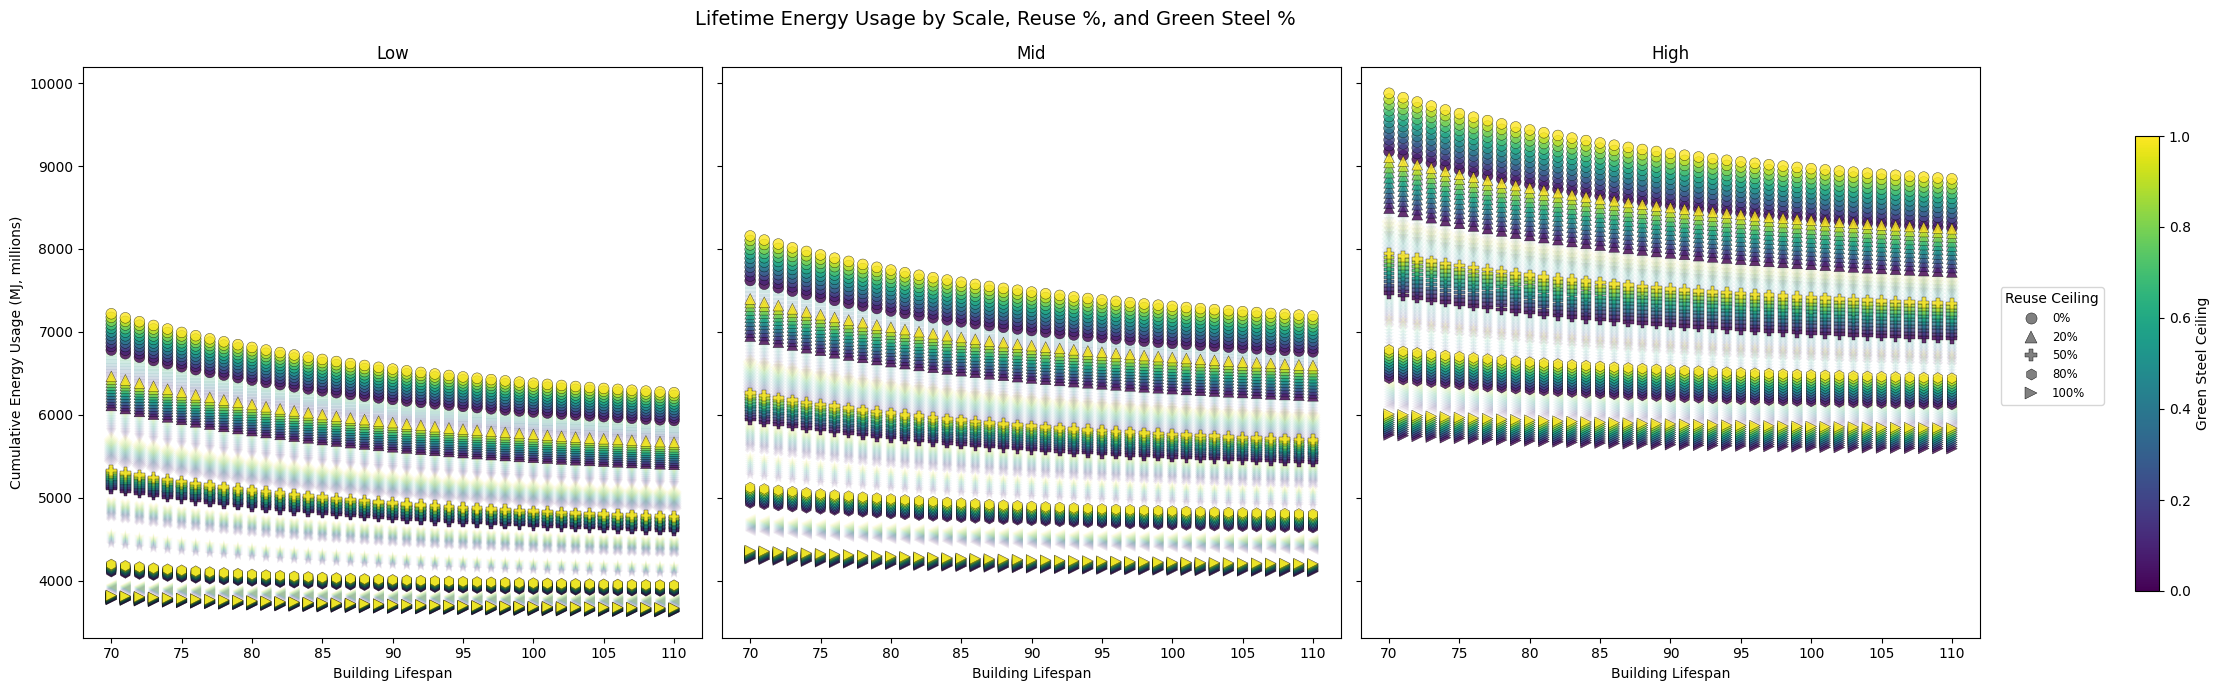

C:\Users\aorga\AppData\Local\Temp\ipykernel_16880\2586498136.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(fig_dir / 'energy_sensitivity.png', dpi = 300, bbox_inches='tight')


In [85]:
def plot_scale_vs_energy_grid(df_lifetime, title=None,
                                x_col='lifetime', y_col='cumulative_energy',
                                shape_col='B_reuse', color_col='B_green',
                                cmap='viridis', figsize=(20, 7),
                                highlight_reuse=(0.0, 0.2, 0.5, 0.8, 1.0),
                                highlight_alpha=0.8, dim_alpha=0.08):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime energy usage (millions of MJ), marker shape = reuse %,
    color = green steel %. Only reuse levels in `highlight_reuse` are shown fully opaque;
    all others are faded.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MJ'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    # tolerance-based match against highlight_reuse, to avoid float equality issues
    highlight_set = set(np.round(highlight_reuse, 6))

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    y_min, y_max = df_lifetime['y_MJ'].min(), df_lifetime['y_MJ'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        # plot dim (non-highlighted) points first, so highlighted ones draw on top
        for reuse_val in reuse_levels:
            is_highlighted = round(reuse_val, 6) in highlight_set
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MJ'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=highlight_alpha if is_highlighted else dim_alpha,
                edgecolors='black',
                linewidths=0.3 if is_highlighted else 0,
                zorder=5 if is_highlighted else 1,
            )

        ax.set_xlabel('Building Lifespan')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Energy Usage (MJ, millions)')

    fig.suptitle(title or 'Lifetime Energy Usage by Scale, Reuse %, and Green Steel %', fontsize=14)

    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    cbar_ax = fig.add_axes([1.07, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Green Steel Ceiling')

    # shape legend only for highlighted reuse levels (the ones actually visible)
    highlighted_levels = [lvl for lvl in reuse_levels if round(lvl, 6) in highlight_set]
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in highlighted_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in highlighted_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_energy_grid(df_lifetime_energy)
fig.savefig(fig_dir / 'energy_sensitivity.png', dpi = 300, bbox_inches='tight')